
# Chapter 7: Unsupervised Learning

## Objectives

This chapter explores unsupervised learning techniques for
discovering patterns and structures in unlabeled data.

## Learning Outcomes

- Understand the concept of unsupervised learning.
- Understand clustering and dimensionality reduction.
- Implement K-Means clustering.
- Evaluate cluster quality using the Silhouette Score.
- Visualize high-dimensional data using Principal Component Analysis.



## 1. Theoretical Background

Unsupervised learning is a machine learning approach that identifies
patterns or structures in data without using predefined target labels.

Unlike supervised learning, the algorithm does not learn from
known output labels during training.

Two important unsupervised learning techniques are clustering
and dimensionality reduction.

Clustering groups observations according to their similarity.
K-Means is a clustering algorithm that assigns each observation
to the nearest cluster centroid and iteratively updates the centroids.

Dimensionality reduction transforms data into a lower-dimensional
representation while attempting to preserve important information.

Principal Component Analysis (PCA) creates new orthogonal features
called principal components, ordered by the amount of variance
they explain.

The Silhouette Score evaluates how well an observation fits
within its assigned cluster compared with other clusters.
Its value ranges from -1 to 1, with higher values generally
indicating better-separated clusters.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score


In [2]:

# Load the Iris dataset
iris = load_iris(as_frame=True)

X = iris.data

print("Dataset shape:", X.shape)
print("\nFeature names:")
print(X.columns.tolist())

print("\nFirst five observations:")
display(X.head())

print("\nDescriptive statistics:")
display(X.describe().T)


Dataset shape: (150, 4)

Feature names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

First five observations:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2



Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
sepal length (cm),150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal width (cm),150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal length (cm),150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal width (cm),150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5



## 2. Dataset Description

The Iris dataset contains 150 observations and four numerical features:
sepal length, sepal width, petal length, and petal width.

The original dataset contains three Iris species. However, this
experiment uses only the numerical features and does not use the
species labels to train or evaluate the clustering algorithm.

The goal is to investigate whether K-Means can identify groups
based on similarities in the feature space.

The resulting cluster numbers are arbitrary identifiers. For example,
cluster 0 does not automatically represent a particular species.


In [8]:
X = X.copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

print("Standardized feature statistics:")
display(X_scaled_df.describe().T)

Standardized feature statistics:


,count,mean,std,min,25%,50%,75%,max
sepal length (cm),150.0,-4.736952e-16,1.00335,-1.870024,-0.900681,-0.052506,0.674501,2.492019
sepal width (cm),150.0,-7.815970e-16,1.00335,-2.433947,-0.592373,-0.131979,0.558611,3.090775
petal length (cm),150.0,-4.263256e-16,1.00335,-1.567576,-1.226552,0.336478,0.762758,1.785832
petal width (cm),150.0,-4.736952e-16,1.00335,-1.447076,-1.183812,0.132510,0.790671,1.712096



## 3. Feature Standardization

K-Means uses distances to assign observations to clusters.
Features with larger numerical scales can dominate these distances.

StandardScaler transforms each feature by subtracting its mean
and dividing by its standard deviation.

After standardization, each feature has approximately zero mean
and unit variance.

This transformation allows the clustering algorithm to consider
features on a more comparable scale.

In this experiment, the scaler is fitted to the dataset because
the task is exploratory clustering rather than supervised
prediction. In a production workflow, preprocessing should be
fitted on the appropriate training data to avoid information leakage.


In [10]:
# Menghitung Silhouette Score untuk k = 2 sampai 6

silhouette_results = []

for k in range(2, 7):
    kmeans_temp = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans_temp.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        cluster_labels
    )

    silhouette_results.append({
        "Number of Clusters": k,
        "Silhouette Score": score
    })

# Membuat DataFrame hasil evaluasi
silhouette_df = pd.DataFrame(silhouette_results)

# Menampilkan hasil
display(silhouette_df)

,Number of Clusters,Silhouette Score
0,2,0.581750
1,3,0.459948
2,4,0.386941
3,5,0.345901
4,6,0.317079


## 4. Selecting the Number of Clusters

K-Means requires the number of clusters to be specified in advance.

In this experiment, the Silhouette Score is calculated for different values of k, ranging from 2 to 6.

A higher Silhouette Score generally indicates that observations are well matched to their assigned clusters and separated from other clusters.

However, the highest score does not automatically guarantee that the resulting clusters are the most meaningful for every application. The choice of k should also consider the purpose of the analysis and the interpretability of the resulting groups.

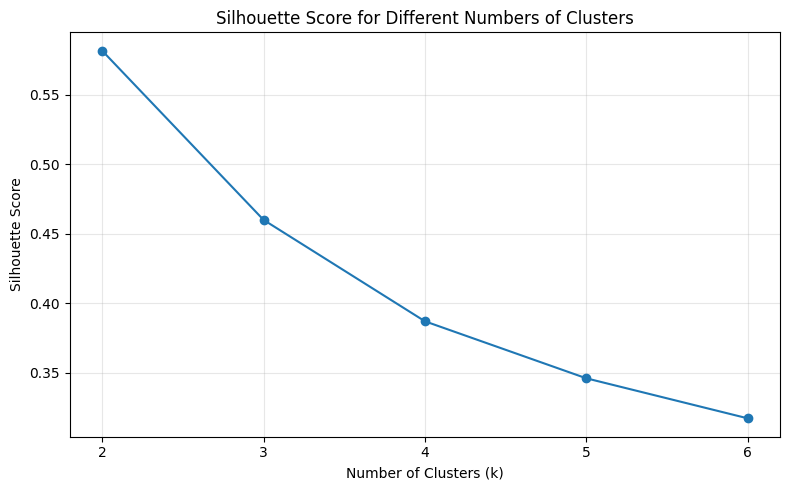

In [11]:
plt.figure(figsize=(8, 5))

plt.plot(
    silhouette_df["Number of Clusters"],
    silhouette_df["Silhouette Score"],
    marker="o"
)

plt.title("Silhouette Score for Different Numbers of Clusters")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 7))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5. K-Means Clustering Results

K-Means groups observations according to their distances from cluster centroids.

The algorithm repeatedly assigns observations to the nearest centroid and updates the centroid positions until convergence or until the iteration limit is reached.

The cluster distribution indicates how many observations belong to each group. The mean feature values help describe the characteristics of each cluster.

Cluster labels such as 0, 1, and 2 are arbitrary identifiers. They do not automatically represent specific Iris species.

## 6. Principal Component Analysis (PCA)

PCA is a dimensionality reduction technique that transforms the original features into a smaller number of principal components.

The first principal component captures the largest possible variance in one direction. The second component captures the largest remaining variance while being orthogonal to the first.

In this experiment, PCA reduces four features to two dimensions to make the clustering results easier to visualize.

The explained variance ratio indicates how much of the original data variance is represented by each component.

Because the data is projected into two dimensions, some information may be lost. K-Means in this experiment is trained using all four standardized features, not only the two PCA components.

## 7. Evaluation Using the Silhouette Score

The Silhouette Score evaluates how well observations fit within their assigned clusters compared with other clusters.

Its value ranges from -1 to 1.

- A value close to 1 generally indicates well-separated clusters.
- A value close to 0 indicates observations near cluster boundaries.
- A negative value may indicate that an observation is closer to another cluster than to its assigned cluster.

The overall score summarizes the clustering quality, but it should not be used as the only criterion for choosing a clustering model.

## 8. Conclusion

This chapter demonstrates the use of unsupervised learning to identify patterns in data without using target labels during training.

K-Means was applied to group observations based on their standardized features. The Silhouette Score was used to evaluate cluster separation, while PCA was used to visualize the clusters in two dimensions.

The results demonstrate that clustering can reveal similarities between observations. However, the resulting clusters must be interpreted carefully because cluster quality depends on the dataset, preprocessing, and choice of algorithm.